# Night table and merged EDA

Presents `data/processed/features.parquet` (`pipelines/03_build_night_table.py`) and the tables of `pipelines/03b_eda_merged.py`. Labels come from the same ERA5-Land reanalysis as the features.

In [1]:
from frostwatch_ml.evaluation import notebook as nb
from frostwatch_ml.evaluation import plots

In [2]:
manifest = nb.load_json("data/processed/features_manifest.json")
print(manifest["night_range"], manifest["rows"], "rows; features from", manifest["feature_allowlist_source"])

['1985-01-02', '2026-10-26'] 122184 rows; features from configs/features.yaml


In [3]:
nb.parquet("data/processed/features.parquet").head()

,point_id,night_date,split,use,t2m_1800_c,d2m_1800_c,dewpoint_depression_1800_c,rh_1800_pct,wind_1800_ms,sp_1800_hpa,ssrd_1800_wm2,strd_1800_wm2,ssrd_afternoon_mean_wm2,strd_afternoon_mean_wm2,skt_1800_c,stl1_1800_c,precip_24h_mm,prev_night_tmin_c,prev_night_frost,cooling_rate_1500_1800_c_per_h,doy_sin,doy_cos,latitude,elevation_proxy_m,sky_emissivity_1800,sky_emissivity_change_1500_1800,afternoon_clearness,cloud_cover_prev_day,frost,tmin_c
0,calamarca,1985-01-02,train,labeled,9.769135,2.618866,7.150269,61.086197,2.651932,626.978577,206.820007,285.853882,569.414490,313.273651,14.094696,14.059479,1.422277,4.149261,0,-0.178640,0.034398,0.999408,-17.0,3860.043457,0.786834,-0.092413,0.634688,0.930916,0,3.701263
1,calamarca,1985-01-03,train,labeled,8.755585,3.795013,4.960571,71.057266,2.746756,626.591431,128.968887,314.646118,545.348328,322.904388,13.496552,13.684540,3.626205,3.701263,0,-0.638550,0.051584,0.998669,-17.0,3860.043457,0.878610,-0.045477,0.607863,0.932601,0,3.384735
2,calamarca,1985-01-04,train,labeled,10.197327,4.085297,6.112030,65.829048,1.708318,625.966492,209.908890,285.963898,754.956482,297.955780,16.673126,15.798859,13.451313,3.384735,0,-0.892812,0.068755,0.997634,-17.0,3860.043457,0.782390,0.011116,0.840229,0.919434,0,3.513336
3,calamarca,1985-01-05,train,labeled,9.693268,2.946503,6.746765,62.839268,2.839300,625.849854,182.698883,313.751678,520.219788,309.863617,14.489471,13.894989,21.178520,3.513336,0,-0.336700,0.085906,0.996303,-17.0,3860.043457,0.864552,0.027301,0.578647,0.904079,0,3.899323
4,calamarca,1985-01-06,train,labeled,9.126099,3.867035,5.259064,69.655632,3.490473,626.741638,196.924438,301.063324,735.318848,303.690613,14.401398,14.361053,2.265770,3.899323,0,-0.496114,0.103031,0.994678,-17.0,3860.043457,0.836276,-0.007735,0.818163,0.935852,0,3.952911


## Class balance by split

In [4]:
nb.csv("data/processed/eda_merged/class_balance.csv")

,rows,frost_nights,frost_rate,majority_class_accuracy
split,,,,
train,73040,27808.0,0.380723,0.619277
validation,23376,7839.0,0.335344,0.664656
test,23376,7476.0,0.319815,0.680185
out_of_sample_check,2384,940.0,0.394295,0.605705


In [5]:
nb.csv("data/processed/eda_merged/frost_by_cell_split.csv").round(3)

,train,validation,test,out_of_sample_check
point_id,,,,
calamarca,0.384,0.342,0.325,0.413
caracollo,0.239,0.202,0.205,0.279
charana,0.660,0.614,0.587,0.674
corocoro,0.527,0.490,0.456,0.527
el_alto,0.215,0.162,0.156,0.215
huanuni,0.406,0.357,0.337,0.440
oruro,0.239,0.193,0.187,0.235
patacamaya,0.376,0.323,0.306,0.372


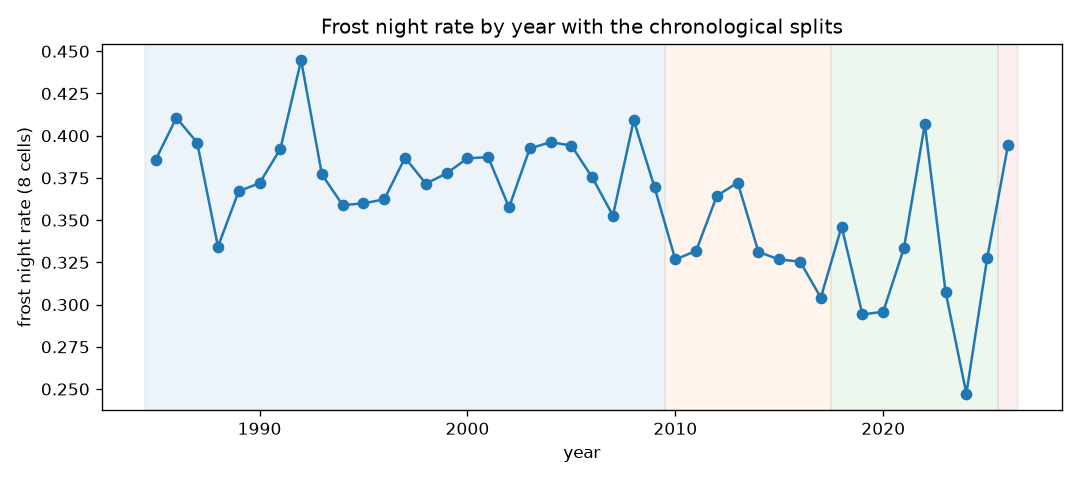

In [6]:
nb.show_figure("docs/figures/merged_frost_rate_by_year.png")

## Drift by split (standardized mean difference vs train)

In [7]:
nb.csv("data/processed/eda_merged/drift_std_mean_diff.csv").round(3)

,train,validation,test,out_of_sample_check
feature,,,,
t2m_1800_c,0.0,0.167,0.305,0.367
d2m_1800_c,0.0,0.040,0.013,-0.172
dewpoint_depression_1800_c,0.0,0.004,0.062,0.243
rh_1800_pct,0.0,-0.011,-0.064,-0.245
wind_1800_ms,0.0,0.047,0.038,0.084
sp_1800_hpa,0.0,0.054,0.106,0.111
ssrd_1800_wm2,0.0,-0.012,0.008,-0.011
strd_1800_wm2,0.0,0.073,0.083,-0.101
ssrd_afternoon_mean_wm2,0.0,-0.022,-0.013,0.035


## Correlation with the label (training years only)

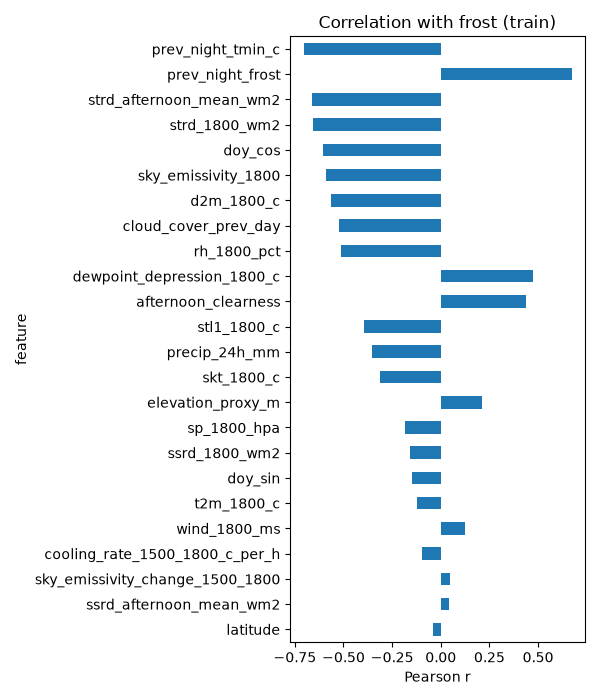

In [8]:
nb.figure(plots.barh(nb.csv("data/processed/eda_merged/corr_with_label_train.csv")["corr_with_frost_train"], "Correlation with frost (train)", "Pearson r"))

## Sign check and agreement with the AgERA5 night minimum

In [9]:
s = nb.load_json("data/processed/eda_merged/summary.json")
print("cloud_cover_prev_day vs sky_emissivity_1800 (train):", round(s["sign_check_corr_cloud_prev_vs_emissivity_train"], 4))
print("label vs AgERA5 agreement:", round(s["label_vs_agera5_agreement_overall"], 4))
nb.csv("data/processed/eda_merged/label_vs_agera5.csv").round(3)

cloud_cover_prev_day vs sky_emissivity_1800 (train): 0.6763
label vs AgERA5 agreement: 0.9012


,nights,agreement,label_frost_rate,agera5_frost_rate,corr_tmin
point_id,,,,,
calamarca,14974,0.920,0.364,0.376,0.942
caracollo,14974,0.919,0.225,0.206,0.932
charana,14974,0.872,0.637,0.549,0.920
corocoro,14974,0.877,0.506,0.395,0.959
el_alto,14974,0.904,0.193,0.224,0.911
huanuni,14974,0.901,0.383,0.420,0.917
oruro,14974,0.908,0.220,0.221,0.943
patacamaya,14974,0.909,0.352,0.336,0.924


## Limitations

See `docs/eda_merged.md`: reanalysis labels, 9 km cells, AgERA5 grid offset in general, lagged cloud proxy, downward frost trend across the chronological splits, no confidence intervals.